In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()
X = df.drop("MedHouseVal", axis=1)

y = df["MedHouseVal"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully!
Dataset shape: (20640, 9)
Input features shape: (20640, 8)
Target shape: (20640,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")
rf_model = RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Random Forest Regressor trained successfully!")

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)
Linear Regression trained successfully!
Random Forest Regressor trained successfully!


In [7]:
# Linear Regression predictions
linear_predictions = linear_model.predict(X_test)

# Random Forest predictions
rf_predictions = rf_model.predict(X_test)
comparison = pd.DataFrame({
    "Actual Price (100k USD)": y_test.values[:10],
    "Linear Regression": linear_predictions[:10],
    "Random Forest": rf_predictions[:10]
})

comparison

,Actual Price (100k USD),Linear Regression,Random Forest
0,0.47700,0.719123,0.509500
1,0.45800,1.764017,0.741610
2,5.00001,2.709659,4.923257
3,2.18600,2.838926,2.529610
4,2.78000,2.604657,2.273690
5,1.58700,2.011754,1.646920
6,1.98200,2.645500,2.376050
7,1.57500,2.168755,1.669320
8,3.40000,2.740746,2.772971
9,4.46600,3.915615,4.913459


In [8]:
# Linear Regression metrics
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_r2 = r2_score(y_test, linear_predictions)

# Random Forest metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_r2 = r2_score(y_test, rf_predictions)

print("LINEAR REGRESSION")
print("MAE:", round(linear_mae, 4))
print("R2 Score:", round(linear_r2, 4))

print("\nRANDOM FOREST REGRESSOR")
print("MAE:", round(rf_mae, 4))
print("R2 Score:", round(rf_r2, 4))
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regressor"
    ],
    "MAE": [
        linear_mae,
        rf_mae
    ],
    "R2 Score": [
        linear_r2,
        rf_r2
    ]
})

results

LINEAR REGRESSION
MAE: 0.5332
R2 Score: 0.5758

RANDOM FOREST REGRESSOR
MAE: 0.3275
R2 Score: 0.8051


,Model,MAE,R2 Score
0,Linear Regression,0.533200,0.575788
1,Random Forest Regressor,0.327543,0.805123


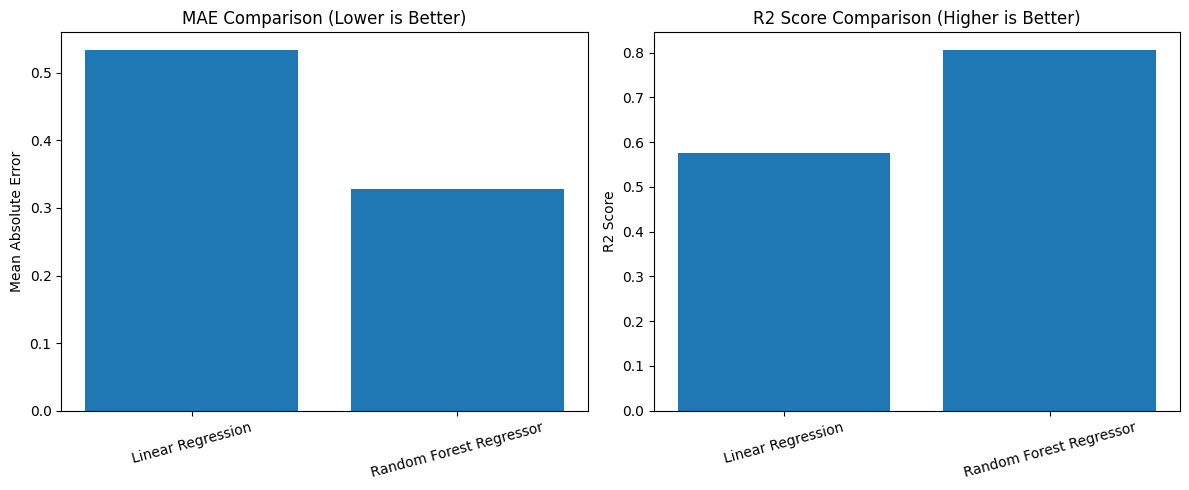

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MAE comparison
axes[0].bar(results["Model"], results["MAE"])
axes[0].set_title("MAE Comparison (Lower is Better)")
axes[0].set_ylabel("Mean Absolute Error")
axes[0].tick_params(axis="x", rotation=15)

# R2 comparison
axes[1].bar(results["Model"], results["R2 Score"])
axes[1].set_title("R2 Score Comparison (Higher is Better)")
axes[1].set_ylabel("R2 Score")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("regression_metrics_comparison.png", dpi=300)
plt.show()

In [10]:
if rf_mae < linear_mae and rf_r2 > linear_r2:
    best_model = rf_model
    best_model_name = "Random Forest Regressor"

elif linear_mae < rf_mae and linear_r2 > rf_r2:
    best_model = linear_model
    best_model_name = "Linear Regression"

else:
    # Use the model with the lower MAE if the metrics disagree
    if rf_mae < linear_mae:
        best_model = rf_model
        best_model_name = "Random Forest Regressor"
    else:
        best_model = linear_model
        best_model_name = "Linear Regression"

print("Selected Model:", best_model_name)
print("Selection based primarily on lower MAE,")
print("with R2 also considered.")

Selected Model: Random Forest Regressor
Selection based primarily on lower MAE,
with R2 also considered.


In [11]:
custom_properties = pd.DataFrame([
    {
        "MedInc": 5.0,
        "HouseAge": 20.0,
        "AveRooms": 5.0,
        "AveBedrms": 1.0,
        "Population": 1000.0,
        "AveOccup": 3.0,
        "Latitude": 34.05,
        "Longitude": -118.25
    },
    {
        "MedInc": 7.5,
        "HouseAge": 30.0,
        "AveRooms": 6.0,
        "AveBedrms": 1.2,
        "Population": 1200.0,
        "AveOccup": 2.8,
        "Latitude": 37.77,
        "Longitude": -122.42
    },
    {
        "MedInc": 3.5,
        "HouseAge": 15.0,
        "AveRooms": 4.5,
        "AveBedrms": 1.1,
        "Population": 800.0,
        "AveOccup": 3.5,
        "Latitude": 36.75,
        "Longitude": -119.78
    }
])

custom_predictions = best_model.predict(custom_properties)

# Dataset target is in units of $100,000
for i, prediction in enumerate(custom_predictions, start=1):
    estimated_price_usd = prediction * 100000

    print(f"Property {i}")
    print(f"Predicted value: ${estimated_price_usd:,.2f}")
    print("-" * 35)

Property 1
Predicted value: $210,513.00
-----------------------------------
Property 2
Predicted value: $425,427.31
-----------------------------------
Property 3
Predicted value: $147,072.00
-----------------------------------


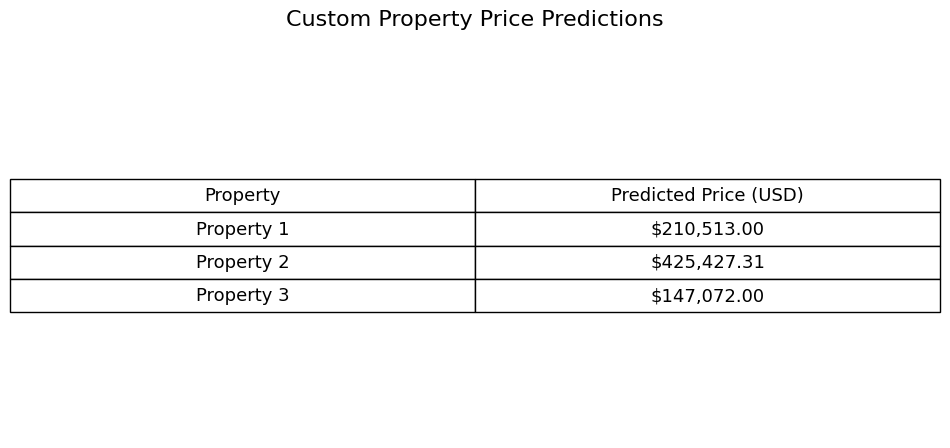

custom_predictions.jpg saved successfully!


In [14]:
import matplotlib.pyplot as plt

# Generate custom prediction output image
fig, ax = plt.subplots(figsize=(12, 5))
ax.axis("off")

table_data = []

for i, prediction in enumerate(custom_predictions, start=1):
    price = prediction * 100000
    table_data.append([
        f"Property {i}",
        f"${price:,.2f}"
    ])

table = ax.table(
    cellText=table_data,
    colLabels=["Property", "Predicted Price (USD)"],
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(13)
table.scale(1, 2)

plt.title(
    "Custom Property Price Predictions",
    fontsize=16,
    pad=20
)

plt.savefig(
    "custom_predictions.jpg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("custom_predictions.jpg saved successfully!")

In [15]:
from google.colab import files

files.download("custom_predictions.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
custom_results = custom_properties.copy()

custom_results["Predicted_MedHouseVal_100k"] = custom_predictions
custom_results["Estimated_Price_USD"] = custom_predictions * 100000

custom_results.to_csv(
    "custom_property_predictions.csv",
    index=False
)

print("Custom property predictions exported successfully!")
results.to_csv("regression_model_comparison.csv", index=False)

print("Project output files saved successfully!")

Custom property predictions exported successfully!
Project output files saved successfully!
